In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.signal import savgol_filter

import ast
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager
from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype'] = 'none'  

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [5]:
data=pd.read_csv('outputs/yeast_experimental_data/blank_corrected_od600_bna1_bna6.csv')

In [6]:
import pandas as pd

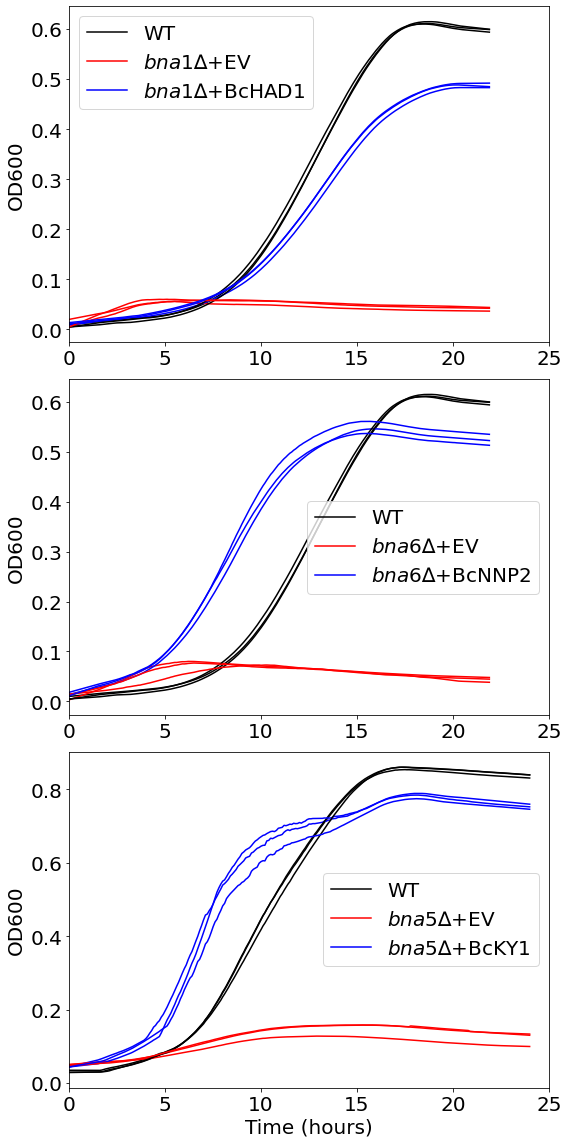

In [13]:
data = pd.read_csv(
    'outputs/yeast_experimental_data/blank_corrected_od600_bna1_bna6.csv'
)

time = np.arange(0, len(data), 1) / 10

fig, axes = plt.subplots(
    3,
    1,
    figsize=(8, 16),
  
)

# --------------------------------------------------
# BNA1 / BcHAD1
# --------------------------------------------------

ax = axes[0]
ax.grid(False)

ax.plot(time, savgol_filter(data['D10'], 31, 1), color='black')
ax.plot(time, savgol_filter(data['D3'], 31, 1), color='red')
ax.plot(time, savgol_filter(data['D6'], 31, 1), color='blue')

ax.legend(
    ['WT', r'$\it{bna1∆}$+EV', r'$\it{bna1∆}$+BcHAD1'],
    fontsize=20
)

ax.plot(time, savgol_filter(data['B10'], 31, 1), color='black')
ax.plot(time, savgol_filter(data['C10'], 31, 1), color='black')

ax.plot(time, savgol_filter(data['B3'], 31, 1), color='red')
ax.plot(time, savgol_filter(data['C3'], 31, 1), color='red')

ax.plot(time, savgol_filter(data['B6'], 31, 1), color='blue')
ax.plot(time, savgol_filter(data['C6'], 31, 1), color='blue')

ax.tick_params(axis='both', labelsize=20)
ax.set_ylabel('OD600', fontsize=20)
ax.set_xlim(0, 25)


# --------------------------------------------------
# BNA6 / BcNNP2
# --------------------------------------------------

ax = axes[1]
ax.grid(False)

ax.plot(time, savgol_filter(data['D10'], 31, 1), color='black')
ax.plot(time, savgol_filter(data['D4'], 31, 1), color='red')
ax.plot(time, savgol_filter(data['D8'], 31, 1), color='blue')

ax.legend(
    ['WT', r'$\it{bna6∆}$+EV', r'$\it{bna6∆}$+BcNNP2'],
    fontsize=20
)

ax.plot(time, savgol_filter(data['B10'], 31, 1), color='black')
ax.plot(time, savgol_filter(data['C10'], 31, 1), color='black')

ax.plot(time, savgol_filter(data['B4'], 31, 1), color='red')
ax.plot(time, savgol_filter(data['C4'], 31, 1), color='red')

ax.plot(time, savgol_filter(data['B8'], 31, 1), color='blue')
ax.plot(time, savgol_filter(data['C8'], 31, 1), color='blue')

ax.tick_params(axis='both', labelsize=20)
ax.set_ylabel('OD600', fontsize=20)
ax.set_xlim(0, 25)


# --------------------------------------------------
# Prepare BNA5 data
# --------------------------------------------------
data=pd.read_csv('outputs/yeast_experimental_data/bradisya_yeast_complementation_bna5.csv')
data_raw = np.array(data.loc[:, 'B4':'D9'])
data_blank = np.array(data.loc[:, 'B3'])

data_corrected = data_raw - np.mean(data_blank)

rep1 = data_corrected[:, 0:5]
rep2 = data_corrected[:, 7:12]
rep3 = data_corrected[:, 14:19]
time = np.arange(0, len(data), 1) / 10


# --------------------------------------------------
# BNA5 / BcKY1
# --------------------------------------------------

ax = axes[2]
ax.grid(False)

ax.plot(time, savgol_filter(rep1[:, 4], 31, 1), color='black')
ax.plot(time, savgol_filter(rep1[:, 0], 31, 1), color='red')
ax.plot(time, savgol_filter(rep1[:, 3], 31, 1), color='blue')

ax.legend(
    ['WT', r'$\it{bna5∆}$+EV', r'$\it{bna5∆}$+BcKY1'],
    fontsize=20
)

ax.plot(time, savgol_filter(rep2[:, 4], 31, 1), color='black')
ax.plot(time, savgol_filter(rep2[:, 0], 31, 1), color='red')
ax.plot(time, savgol_filter(rep2[:, 3], 31, 1), color='blue')

ax.plot(time, savgol_filter(rep3[:, 4], 31, 1), color='black')
ax.plot(time, savgol_filter(rep3[:, 0], 31, 1), color='red')
ax.plot(time, savgol_filter(rep3[:, 3], 31, 1), color='blue')

ax.tick_params(axis='both', labelsize=20)
ax.set_ylabel('OD600', fontsize=20)
ax.set_xlabel('Time (hours)', fontsize=20)
ax.set_xlim(0, 25)


plt.tight_layout()

plt.savefig(
    'figures/Complementation_vertical.svg',
    dpi=1200,
    bbox_inches='tight'
)

plt.show()